<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   country                     2500 non-null   object 
 1   year                        2500 non-null   int64  
 2   quarter                     2500 non-null   object 
 3   trade_volume_usd            2500 non-null   float64
 4   export_value                2500 non-null   float64
 5   import_value                2500 non-null   float64
 6   trade_balance               2500 non-null   float64
 7   supply_chain_dependency     2500 non-null   float64
 8   trade_network_degree        2500 non-null   int64  
 9   network_centrality_score    2500 non-null   float64
 10  clustering_coefficient      2500 non-null   float64
 11  sanction_exposure_index     2500 non-null   float64
 12  sanction_event              2500 non-null   int64  
 13  digital_trade_index         2500 

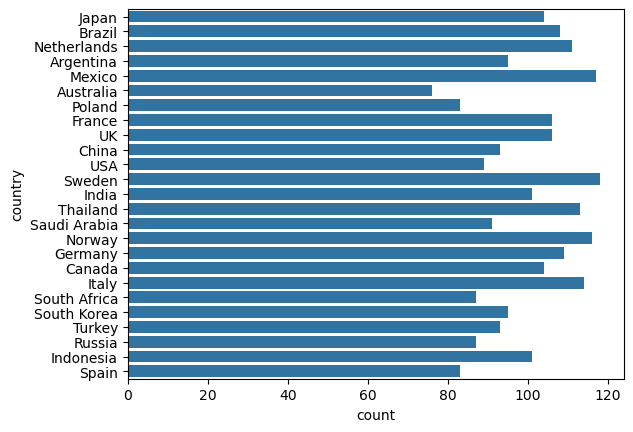

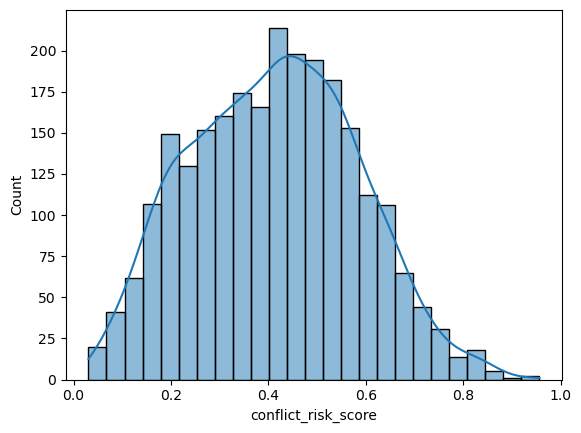

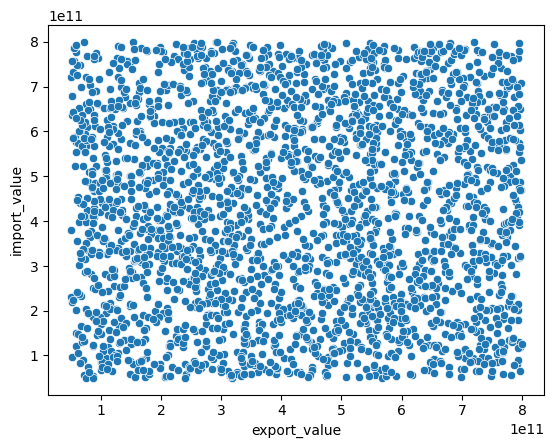

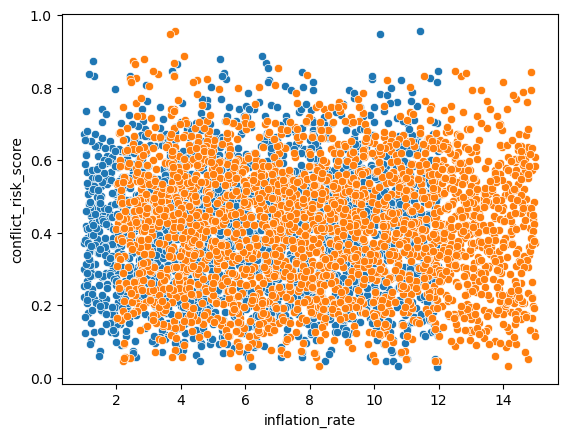

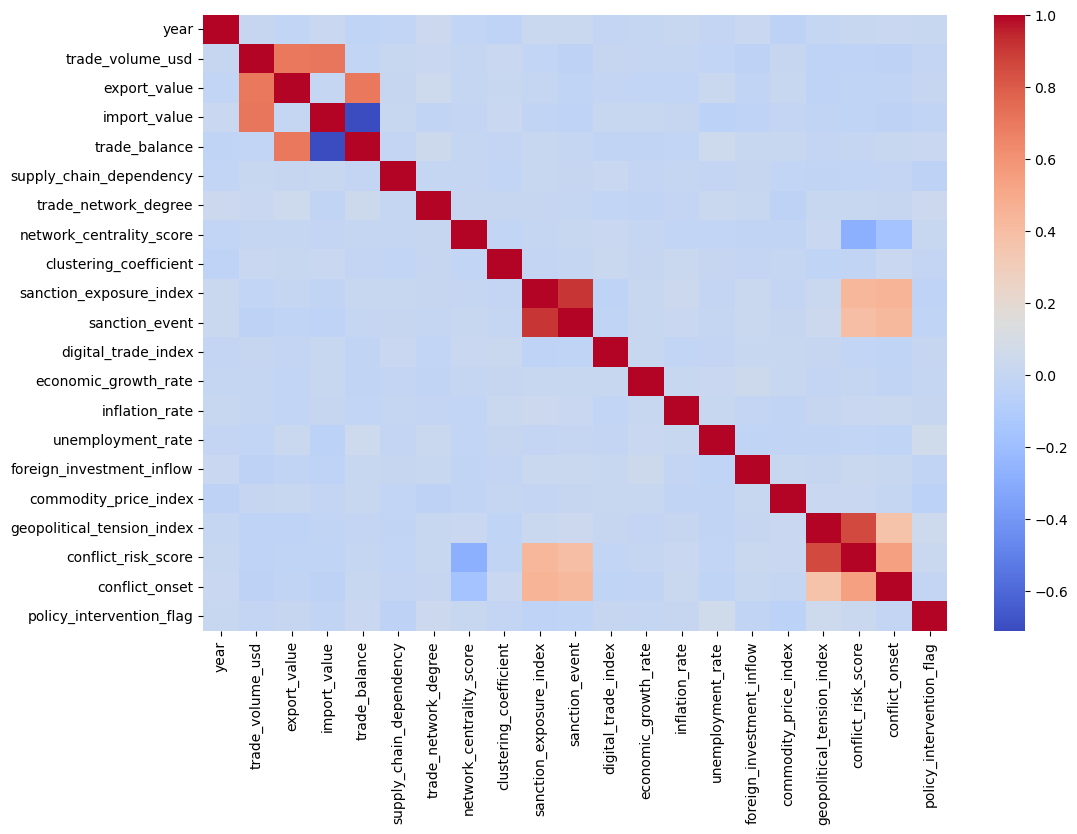

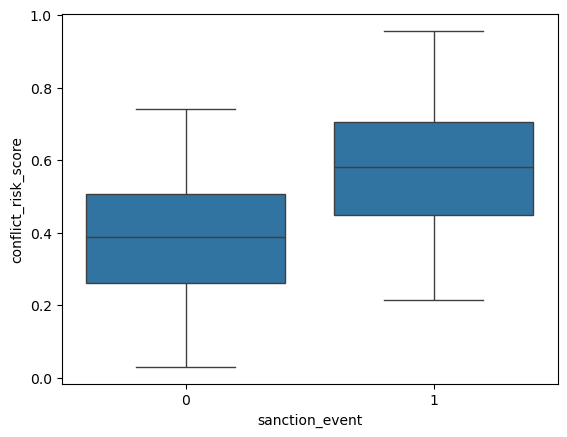

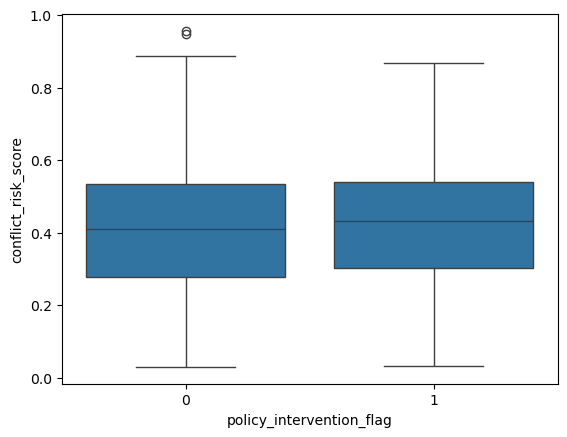

In [28]:
#perform EDA

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("global_trade_conflict_risk_dataset.csv")

df.head()

df.columns
df.info()
df.describe()
df.shape

df.isnull().sum()

df['country'].value_counts()

#visualization
sns.countplot(y='country',data=df)
plt.show()

#conflict risk distribution
sns.histplot(df['conflict_risk_score'], kde=True)
plt.show()

#trade analysis
sns.scatterplot(x='export_value', y='import_value',data=df)
plt.show()

#economic indiactors
sns.scatterplot(x='inflation_rate', y='conflict_risk_score', data=df)

sns.scatterplot(x='unemployment_rate', y='conflict_risk_score', data=df)
plt.show()

#corellation analysis
corr = df.corr(numeric_only=True)
plt.figure(figsize=(12,8))
sns.heatmap(corr, cmap="coolwarm")
plt.show()

#conflict vs sanction
sns.boxplot(x='sanction_event', y='conflict_risk_score', data=df)
plt.show()

#policy intervention impact
sns.boxplot(x='policy_intervention_flag', y='conflict_risk_score', data=df)
plt.show()

In [39]:
#performing preprocessing

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler

df = pd.read_csv("global_trade_conflict_risk_dataset.csv")
df.head()
df.isnull().sum()

df.fillna(df.mean(numeric_only=True), inplace=True)

df.duplicated().sum()
df.drop_duplicates(inplace=True)

le = LabelEncoder()

df['country'] = le.fit_transform(df['country'])
df['quarter'] = le.fit_transform(df['quarter'])

#feature selection
X = df.drop(['conflict_onset'], axis=1)
y = df['conflict_onset']

#feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42)

#check final dataset
X_train.shape
X_test.shape

#check split results
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2000, 22)
(500, 22)
(2000,)
(500,)


In [44]:
# model training & evaluation

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model  import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("global_trade_conflict_risk_dataset.csv")

le = LabelEncoder()

#Encode Categorical Columns
df['country'] = le.fit_transform(df['country'])
df['quarter'] = le.fit_transform(df['quarter'])

#Define Features (X) and Target (y)
X = df.drop('conflict_onset', axis=1)
y = df['conflict_onset']

#Feature Scaling
scaler = StandardScaler()
X = scaler.fit_transform(X)

#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#train model
model = LogisticRegression()
model.fit(X_train,y_train)

#make prediction
y_pred = model.predict(X_test)

#evaluate model
accuracy = accuracy_score(y_test, y_pred)
print("accuracy:", accuracy)

#confudion matrix
print(confusion_matrix(y_test, y_pred))

#classificaton report
print(classification_report(y_test, y_pred))


accuracy: 0.996
[[456   1]
 [  1  42]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       457
           1       0.98      0.98      0.98        43

    accuracy                           1.00       500
   macro avg       0.99      0.99      0.99       500
weighted avg       1.00      1.00      1.00       500

